# Exercise 4. Flipkart customer review analytics

This notebook uses the original [Flipkart Product Reviews with Sentiment
dataset by Nirali Vaghani](https://www.kaggle.com/datasets/niraliivaghani/flipkart-product-customer-reviews-dataset).

In [1]:
!pip install wordcloud

In [6]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
from wordcloud import STOPWORDS, WordCloud


dataset_path = Path("Dataset-SA.csv").expanduser()

if dataset_path == Path("Dataset-SA.csv") and not dataset_path.is_file():
    for zip_name in (
        "flipkart-product-customer-reviews-dataset.zip",
        "archive.zip",
        "flipkart_reviews.zip",
    ):
        if Path(zip_name).is_file():
            dataset_path = Path(zip_name)
            break

if not dataset_path.is_file():
    raise FileNotFoundError(
        f"Dataset file not found: {dataset_path.resolve()}. "
        "Set dataset_path to your downloaded CSV or ZIP."
    )

if dataset_path.suffix.lower() == ".zip":
    with ZipFile(dataset_path) as archive:
        with archive.open("Dataset-SA.csv") as csv_file:
            df = pd.read_csv(csv_file, low_memory=False)
else:
    df = pd.read_csv(dataset_path, low_memory=False)

print(f"Loaded {len(df):,} rows.")
print("Columns:", ", ".join(df.columns))

Loaded 205,052 rows.
Columns: product_name, product_price, Rate, Review, Summary, Sentiment


# 2. Clean the ratings and prices
Convert ratings and prices to numbers. Keep ratings from 1 to 5 and nonnegative prices. Treat unparseable or out-of-range values as missing. Exclude rows with no product name or with both numeric fields missing. If only one field is missing, the other can still contribute to its mean.

In [7]:
df["product_name"] = df["product_name"].astype("string").str.strip().replace("", pd.NA)

ratings = pd.to_numeric(df["Rate"].astype("string").str.strip(), errors="coerce")
df["Rate"] = ratings.where(ratings.between(1, 5))

price_text = (
    df["product_price"].astype("string").str.strip()
    .str.replace(r"^(?:₹|INR)\s*", "", regex=True, case=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
prices = pd.to_numeric(price_text, errors="coerce")
df["product_price"] = prices.where(prices.ge(0))

print(f"Missing or invalid ratings: {df['Rate'].isna().sum():,}")
print(f"Missing or invalid prices: {df['product_price'].isna().sum():,}")

original_count = len(df)
df = df.dropna(subset=["product_name"])
df = df.dropna(subset=["Rate", "product_price"], how="all").copy()
print(f"Excluded rows: {original_count - len(df):,}")

Missing or invalid ratings: 3
Missing or invalid prices: 3
Excluded rows: 3


The word cloud counts individual English-letter tokens from all nonempty summaries.
It excludes common stop words and one-letter tokens. Larger words appear more often.

# 3. Compute the mean rating and mean price per product
items contains one row per distinct product name. Each mean uses the available values from that product's review records.

In [8]:
items = df.groupby("product_name", as_index=False).agg(
    mean_rating=("Rate", "mean"),
    mean_price=("product_price", "mean"),
)

print(f"Products summarized: {len(items):,}")
items.head(10)

Products summarized: 958


,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.986667,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.406915,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.888889,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
5,77085PP03 Volt Analog Watch For Men,4.711111,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.6875,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.803571,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.516129,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.455,279.0


# 4. Visualize frequent terms in Summary
Remove missing and blank summaries, links, and common English stop words. Keep negation words such as not and never because they matter in customer feedback. Larger words occur more often in the cleaned summaries.

Nonblank summaries used: 205,038


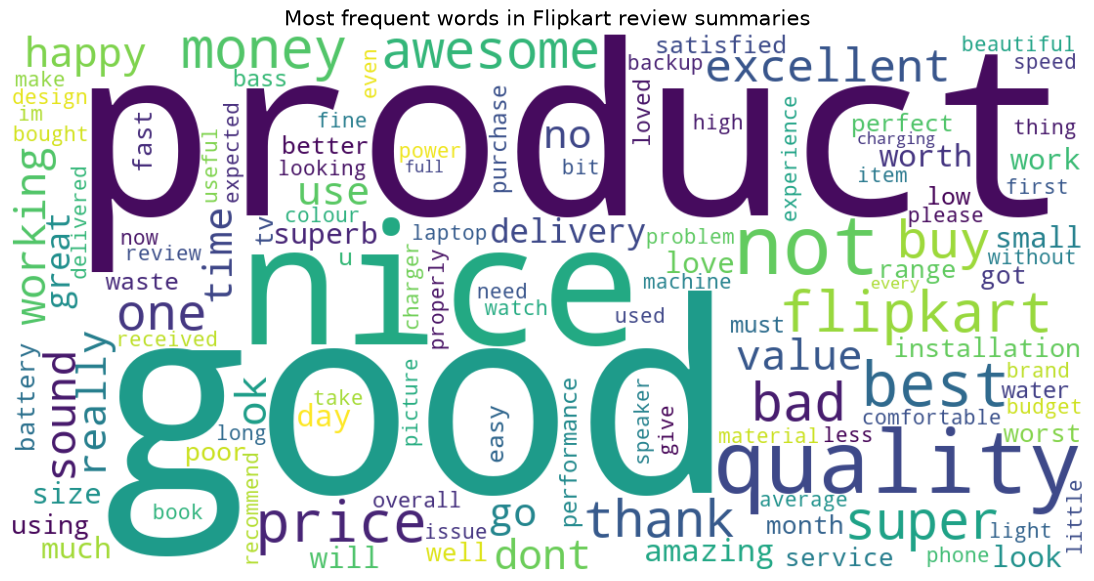

In [9]:
summaries = (
    df["Summary"].dropna().astype("string")
    .str.replace(r"https?://\S+|www\.\S+", "", regex=True)
    .str.strip().str.lower()
)
summaries = summaries[summaries.ne("")]
summary_text = " ".join(summaries)
stop_words = (set(STOPWORDS) - {"no", "not", "never"}) | {"nan"}

cloud = WordCloud(
    width=1100,
    height=550,
    background_color="white",
    colormap="viridis",
    stopwords=stop_words,
    collocations=False,
    random_state=42,
    max_words=120,
).generate(summary_text)

print(f"Nonblank summaries used: {len(summaries):,}")
fig, ax = plt.subplots(figsize=(11, 5.7), layout="constrained")
ax.imshow(cloud, interpolation="bilinear")
ax.set_title("Most frequent words in Flipkart review summaries", fontsize=15)
ax.set_axis_off()
plt.show()